In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import statsmodels.stats.api as sms
from scipy.stats import (ttest_1samp, shapiro, levene, ttest_ind, mannwhitneyu,
                         pearsonr, spearmanr, kendalltau, f_oneway, kruskal)
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multicomp import MultiComparison


In [9]:
url = "https://github.com/devtlv/Datasets-DA-Bootcamp-2-/raw/refs/heads/main/Week%208%20-%20Hackathon%20&%20AB%20Testing/W8D3%20-%20AB%20Testing/AB_Test_Results.zip"
df = pd.read_csv(url, compression="zip")
print(df.shape)
df.head()

(10000, 3)


,USER_ID,VARIANT_NAME,REVENUE
0,737,variant,0.0
1,2423,control,0.0
2,9411,control,0.0
3,7311,control,0.0
4,6174,variant,0.0


# Data Understanding

In [10]:
print("Shape:", df.shape)
print("\n--- Info ---")
df.info()
print("\n--- Columns ---")
print(list(df.columns))
print("\n--- Missing values ---")
print(df.isna().sum())
print("\n--- Descriptive statistics ---")
print(df.describe())
print("\n--- VARIANT_NAME counts ---")
print(df["VARIANT_NAME"].value_counts())
print("\n--- Unique USER_ID ---")
print("Unique users:", df["USER_ID"].nunique(), "of", len(df), "rows")

# extra checks for data problems
print("\n--- Extra checks ---")
print("Fully duplicated rows:", df.duplicated().sum())
print("Rows with a repeated USER_ID:", df["USER_ID"].duplicated(keep=False).sum())
dup_users = df.groupby("USER_ID")["VARIANT_NAME"].nunique()
print("Users who appear in BOTH variant and control:", (dup_users > 1).sum())
print("Negative revenue rows:", (df["REVENUE"] < 0).sum())
print("Share of rows with REVENUE == 0:", round((df["REVENUE"] == 0).mean(), 4))
print("Top 5 revenue values:", df["REVENUE"].nlargest(5).tolist())
print("Variant name spellings:", df["VARIANT_NAME"].unique())

Shape: (10000, 3)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   USER_ID       10000 non-null  int64  
 1   VARIANT_NAME  10000 non-null  str    
 2   REVENUE       10000 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 234.5 KB

--- Columns ---
['USER_ID', 'VARIANT_NAME', 'REVENUE']

--- Missing values ---
USER_ID         0
VARIANT_NAME    0
REVENUE         0
dtype: int64

--- Descriptive statistics ---
            USER_ID       REVENUE
count  10000.000000  10000.000000
mean    4981.080200      0.099447
std     2890.590115      2.318529
min        2.000000      0.000000
25%     2468.750000      0.000000
50%     4962.000000      0.000000
75%     7511.500000      0.000000
max    10000.000000    196.010000

--- VARIANT_NAME counts ---
VARIANT_NAME
variant    5016
control    4984
Name: count, dtype: int64

--- Unique 

# Average Revenue by VARIANT_NAME

In [11]:
summary = df.groupby("VARIANT_NAME")["REVENUE"].agg(["count", "mean", "median", "std", "sum", "max"]).round(4)
summary["paying_rows"] = (df["REVENUE"] > 0).groupby(df["VARIANT_NAME"]).sum()
summary["share_paying"] = (summary["paying_rows"] / summary["count"]).round(4)
summary

,count,mean,median,std,sum,max,paying_rows,share_paying
VARIANT_NAME,,,,,,,,
control,4984,0.1290,0.0,3.0075,643.00,196.01,80,0.0161
variant,5016,0.0701,0.0,1.3148,351.47,58.63,72,0.0144


What if H0: M1 = M2 ?
What about H1: M1 1= M2 ?

H0: the mean revenue of control equals the mean revenue of variant (M1 = M2), meaning the change had no effect.
H1: the mean revenues differ (M1 ≠ M2), meaning the change had an effect.

# Assumptions Control:
*# 1- Normality Assumptions*
*# 2- Homogeneity of Variances Assumption*

In [12]:
control = df.loc[df["VARIANT_NAME"] == "control", "REVENUE"]
variant = df.loc[df["VARIANT_NAME"] == "variant", "REVENUE"]

stat_c, p_c = shapiro(control)
stat_v, p_v = shapiro(variant)
print("control: statistic =", round(stat_c, 4), " p-value =", p_c)
print("variant: statistic =", round(stat_v, 4), " p-value =", p_v)

control: statistic = 0.0183  p-value = 2.4983282342756495e-95
variant: statistic = 0.027  p-value = 2.7310101383895778e-95


c:\Users\Frenki\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5016.
  res = hypotest_fun_out(*samples, **kwds)


Conclusion: p-values are far below 0.05 in both groups -> revenue is NOT normally distributed -> use a non-parametric test (Mann-Whitney U).

In [13]:
stat_l, p_l = levene(control, variant)
print("Levene: statistic =", round(stat_l, 4), " p-value =", p_l)

Levene: statistic = 1.6159  p-value = 0.20370007853373562


Conclusion: p-value (0.204) > 0.05 -> we do not reject equal variances; the two groups have similar variance.

# Non-Parametric Test (mannwhitneyu Test)

In [14]:
stat_mw, p_mw = mannwhitneyu(control, variant, alternative="two-sided")
print("Mann-Whitney U: statistic =", stat_mw, " p-value =", p_mw)

Mann-Whitney U: statistic = 12521564.0  p-value = 0.47825247965294926


Conclusion: p-value (0.478) > 0.05 -> we do not reject H0. There is no statistically significant difference in revenue between control and variant, so we have no evidence that the change affected revenue.

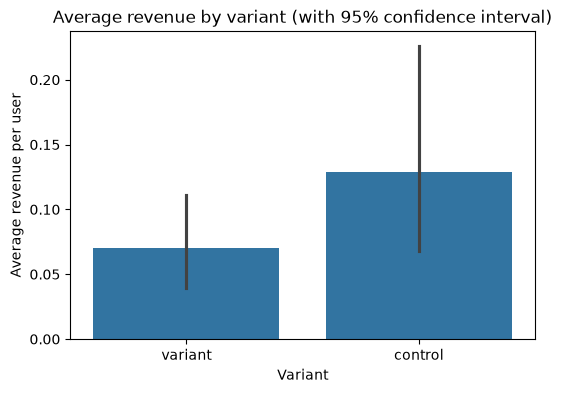

In [15]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="VARIANT_NAME", y="REVENUE", errorbar="ci")
plt.title("Average revenue by variant (with 95% confidence interval)")
plt.xlabel("Variant")
plt.ylabel("Average revenue per user")
plt.show()

In [16]:
# EXTRA CHECK: repeat the test on cleaned data
# - drop users who appear in BOTH groups (1,541 users)
# - drop exact duplicate rows
users_in_both = df.groupby("USER_ID")["VARIANT_NAME"].nunique()
ids_in_both = users_in_both[users_in_both > 1].index

clean = df[~df["USER_ID"].isin(ids_in_both)].drop_duplicates()
print("Rows before:", len(df), "| after cleaning:", len(clean))
print(clean["VARIANT_NAME"].value_counts())
print(clean.groupby("VARIANT_NAME")["REVENUE"].agg(["count", "mean", "sum", "max"]).round(4))

c_clean = clean.loc[clean["VARIANT_NAME"] == "control", "REVENUE"]
v_clean = clean.loc[clean["VARIANT_NAME"] == "variant", "REVENUE"]
stat_cl, p_cl = mannwhitneyu(c_clean, v_clean, alternative="two-sided")
print("\nMann-Whitney U (clean data): statistic =", stat_cl, " p-value =", p_cl)

Rows before: 10000 | after cleaning: 4821
VARIANT_NAME
control    2414
variant    2407
Name: count, dtype: int64
              count    mean     sum     max
VARIANT_NAME                               
control        2414  0.1949  470.56  196.01
variant        2407  0.0745  179.32   23.04

Mann-Whitney U (clean data): statistic = 2918468.0  p-value = 0.26069244720791673


# Conclusion (clean data): p-value (0.261) > 0.05 -> same conclusion as with the full data: no statistically significant difference in revenue between control and variant.